### Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, confusion_matrix

from collections import Counter
pd.set_option("use_inf_as_na", True)

# Load Data
data = pd.read_pickle("data_small.pkl")

# Clean Data
data = data.copy()
data.replace([np.inf, -np.inf], np.nan, inplace=True)
data = data.ffill().fillna(0)

# Make sure we have a date index like the notebook
data = data.reset_index()
data["date"] = pd.to_datetime(data["date"])
data = data.set_index("date").sort_index()

/var/folders/vf/ml0jt6z91qsdhgg6jwg8p76h0000gn/T/ipykernel_5480/3000275188.py:10: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  pd.set_option("use_inf_as_na", True)


### Q1

#### Create Binary Labels

In [2]:
d = data["next_period_return"] - data["spy_next_period_return"]

data["rel_performance"] = np.where(d > 0, 1, -1)

#### Fit the Model (Copied from "Tree Strategy.ipynb")

Train label counts: Counter({np.int64(1): 12691, np.int64(-1): 10726})
Valid label counts: Counter({np.int64(1): 555, np.int64(-1): 397})
Test  label counts: Counter({np.int64(1): 693, np.int64(-1): 473})
Train accuracy: 0.606482470000427
Valid accuracy: 0.532563025210084
Num selected features: 74
Valid pred counts: Counter({np.int64(1): 690, np.int64(-1): 262})
Confusion matrix (valid):
 [[107 155]
 [290 400]]
Valid profit (sum preds*rets): 64.08459700000003
Test  profit (sum preds*rets): 39.01689600000001


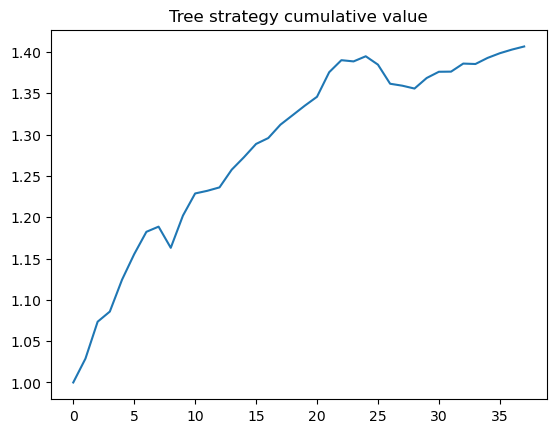

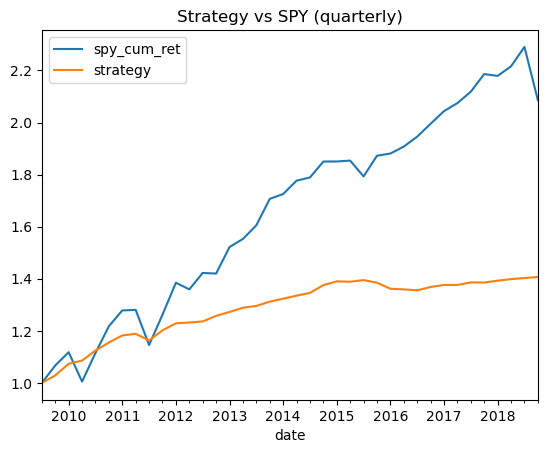

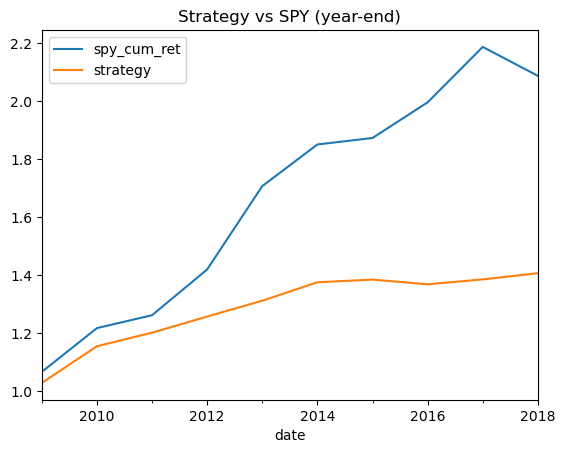

Strategy Sharpe: 0.714751426156683
SPY Sharpe: 0.4273282941267868
beta: 0.10716303313760103
IR: 0.584416020397947
alpha: 0.007844866637818998


In [3]:
# Train/Test Splits
df_train = data.loc["2004-01-01":"2009-01-01"]
df_valid = data.loc["2009-04-01":"2009-07-01"]
df_test  = data.loc["2009-10-01":"2010-01-01"]

train_stock_returns = df_train["next_period_return"]
valid_stock_returns = df_valid["next_period_return"]
test_stock_returns  = df_test["next_period_return"]

drop_cols = [
    "ticker", "date",
    "next_period_return", "spy_next_period_return",
    "rel_performance", "pred_rel_return",
    "return", "cum_ret", "spy_cum_ret"
]

train = df_train.reset_index().drop(drop_cols, axis=1, errors="ignore")
valid = df_valid.reset_index().drop(drop_cols, axis=1, errors="ignore")
test  = df_test.reset_index().drop(drop_cols, axis=1, errors="ignore")

# Keep ONLY numeric features
train = train.select_dtypes(include=[np.number]).copy()
valid = valid.select_dtypes(include=[np.number]).copy()
test  = test.select_dtypes(include=[np.number]).copy()

scaler = MinMaxScaler()
float_vars = [c for c in train.columns if np.issubdtype(train[c].dtype, np.number)]

train[float_vars] = scaler.fit_transform(train[float_vars])
valid[float_vars] = scaler.transform(valid[float_vars])
test[float_vars]  = scaler.transform(test[float_vars])

y_train = df_train["rel_performance"].values
y_valid = df_valid["rel_performance"].values
y_test  = df_test["rel_performance"].values

print("Train label counts:", Counter(y_train))
print("Valid label counts:", Counter(y_valid))
print("Test  label counts:", Counter(y_test))

# Base Tree & Feature Importance
t_clf = DecisionTreeClassifier(min_samples_leaf=200, max_depth=15, random_state=123)
t_clf.fit(train, y_train)

print("Train accuracy:", accuracy_score(y_train, t_clf.predict(train)))
print("Valid accuracy:", accuracy_score(y_valid, t_clf.predict(valid)))

fi = pd.DataFrame({"cols": train.columns, "feat_imp": t_clf.feature_importances_}).sort_values("feat_imp", ascending=False)
features = fi[fi["feat_imp"] > 0.0].copy()
cols = features["cols"].values

if len(cols) == 0:
    cols = fi["cols"].head(20).values

print("Num selected features:", len(cols))


# Reduced Feature Set & Rescale
scaler2 = MinMaxScaler()
train_red = pd.DataFrame(scaler2.fit_transform(train[cols].values), columns=cols)
valid_red = pd.DataFrame(scaler2.transform(valid[cols].values), columns=cols)
test_red  = pd.DataFrame(scaler2.transform(test[cols].values), columns=cols)

t_clf.fit(train_red, y_train)

pred_valid = t_clf.predict(valid_red)
pred_test  = t_clf.predict(test_red)

print("Valid pred counts:", Counter(pred_valid))
print("Confusion matrix (valid):\n", confusion_matrix(pred_valid, y_valid))

profit_valid = (pred_valid * df_valid["next_period_return"].values).sum()
profit_test  = (pred_test  * df_test["next_period_return"].values).sum()

print("Valid profit (sum preds*rets):", profit_valid)
print("Test  profit (sum preds*rets):", profit_test)

# Rolling Tree Strategy Backtest
shap_factors = [c for c in cols if c in data.columns]
if len(shap_factors) == 0:
    shap_factors = list(train.columns)

start_dates = [pd.to_datetime("2004-02-01") + pd.DateOffset(months=3*i) for i in range(38)]
end_dates   = [d + pd.DateOffset(months=60) for d in start_dates]

training_frames = [data.loc[d : d + pd.DateOffset(months=60)] for d in start_dates]
test_frames     = [data.loc[d + pd.DateOffset(months=6) : d + pd.DateOffset(months=9)] for d in end_dates]
training_labels = [f["rel_performance"].values for f in training_frames]

scalers = [MinMaxScaler() for _ in range(len(training_frames))]

opt_training_data = []
opt_test_data = []

for i in range(len(training_frames)):
    tr = training_frames[i]
    te = test_frames[i]

    if len(tr) == 0 or len(te) == 0:
        opt_training_data.append(pd.DataFrame(columns=shap_factors))
        opt_test_data.append(pd.DataFrame(columns=shap_factors))
        continue

    X_tr = tr[shap_factors].select_dtypes(include=[np.number]).copy()
    X_te = te[shap_factors].select_dtypes(include=[np.number]).copy()

    # align columns
    common_cols = [c for c in shap_factors if c in X_tr.columns and c in X_te.columns]
    X_tr = X_tr[common_cols]
    X_te = X_te[common_cols]

    if len(common_cols) == 0:
        opt_training_data.append(pd.DataFrame())
        opt_test_data.append(pd.DataFrame())
        continue

    s = scalers[i]
    opt_training_data.append(pd.DataFrame(s.fit_transform(X_tr.values), columns=common_cols))
    opt_test_data.append(pd.DataFrame(s.transform(X_te.values), columns=common_cols))

x = [1.0]
ret = []

n_steps = min(len(start_dates)-1, len(opt_training_data)-1, len(opt_test_data)-1)

for i in range(n_steps):
    if opt_training_data[i].shape[0] == 0 or opt_test_data[i].shape[0] == 0:
        x.append(x[-1])
        ret.append(0.0)
        continue

    y_i = training_labels[i]
    X_i = opt_training_data[i]
    Z_i = opt_test_data[i]

    if len(y_i) != len(X_i):
        m = min(len(y_i), len(X_i))
        y_i = y_i[:m]
        X_i = X_i.iloc[:m].copy()

    t_clf.fit(X_i, y_i)

    preds = t_clf.predict(Z_i)
    profit_i = (preds * test_frames[i]["next_period_return"].values[:len(preds)]).sum()

    ret.append(profit_i)
    num_names = len(Z_i)
    x.append(x[i] + (x[i] / num_names) * profit_i)

plt.plot(x)
plt.title("Tree strategy cumulative value")
plt.show()


# SPY Buy-And-Hold Comparison
if "spy_cum_ret" not in data.columns:
    raise ValueError("Need 'spy_cum_ret' in data to compare with SPY buy-and-hold.")

SPY = (
    data.reset_index()[["date", "spy_cum_ret"]]
    .drop_duplicates("date")
    .set_index("date")
    .sort_index()
)

SPY = SPY.loc["2009-08-03":"2024-08-01"].resample("QE").ffill()
SPY["spy_cum_ret"] = SPY["spy_cum_ret"] - SPY["spy_cum_ret"].iloc[0] + 1.0

m = min(len(SPY), len(x))
SPY = SPY.iloc[:m].copy()
SPY["strategy"] = x[:m]

SPY.plot()
plt.title("Strategy vs SPY (quarterly)")
plt.show()

SPY_y = SPY.resample("YE").ffill()
SPY_y.plot()
plt.title("Strategy vs SPY (year-end)")
plt.show()

strategy_ret = (SPY["strategy"] - 1.0).diff()
spy_ret = (SPY["spy_cum_ret"] - 1.0).diff()

strategy_mean = strategy_ret.mean()
strategy_std  = strategy_ret.std()
spy_mean      = spy_ret.mean()
spy_std       = spy_ret.std()

print("Strategy Sharpe:", strategy_mean / strategy_std)
print("SPY Sharpe:", spy_mean / spy_std)

sr = strategy_ret.values[1:]
mr = spy_ret.values[1:]

beta = (np.cov(mr, sr) / np.var(mr))[1, 0]
resid = sr - beta * mr
IR = np.mean(resid) / np.std(resid)
alpha = np.mean(resid)

print("beta:", beta)
print("IR:", IR)
print("alpha:", alpha)

### Q2

#### Create Labels

In [4]:
d = data["next_period_return"] - data["spy_next_period_return"]

# Create 5 labels
y = np.zeros(len(d), dtype=int)
y[d > 0.05] = 2
y[(d > 0.01) & (d <= 0.05)] = 1
y[(d >= -0.01) & (d <= 0.01)] = 0
y[(d < -0.01) & (d >= -0.05)] = -1
y[d < -0.05] = -2

data["rel_performance"] = y

#### Fit the Model (Copied from "Tree Strategy.ipynb")

Train label counts: Counter({np.int64(2): 8885, np.int64(-2): 6961, np.int64(1): 3011, np.int64(-1): 2707, np.int64(0): 1853})
Valid label counts: Counter({np.int64(2): 398, np.int64(-2): 255, np.int64(1): 122, np.int64(-1): 109, np.int64(0): 68})
Test  label counts: Counter({np.int64(2): 469, np.int64(-2): 249, np.int64(1): 173, np.int64(-1): 163, np.int64(0): 112})
Train accuracy: 0.4220011103044797
Valid accuracy: 0.3550420168067227
Num selected features: 75
Valid pred counts: Counter({np.int64(2): 712, np.int64(-2): 240})
Confusion matrix (valid):
 [[ 60  22  10  28 120]
 [  0   0   0   0   0]
 [  0   0   0   0   0]
 [  0   0   0   0   0]
 [195  87  58  94 278]]
Valid profit (sum preds*rets): 130.21108599999997
Test  profit (sum preds*rets): 24.23077200000006


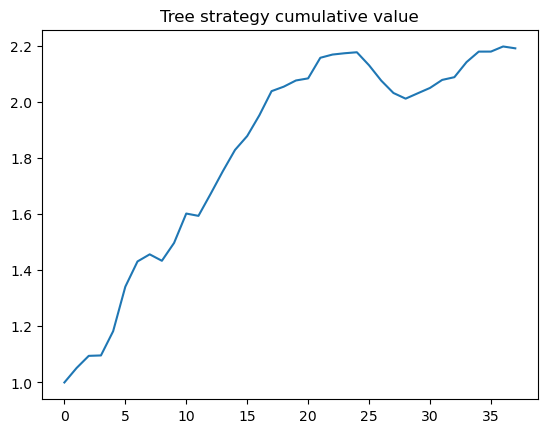

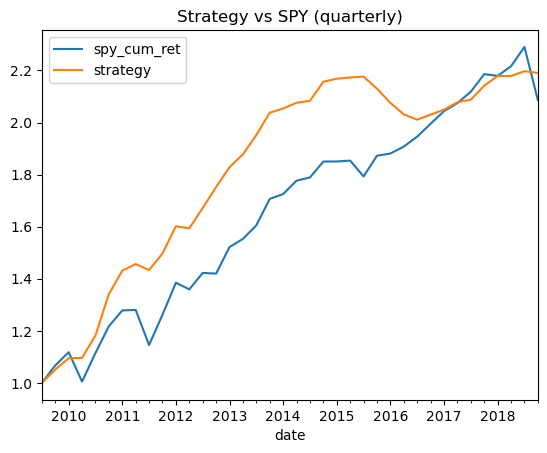

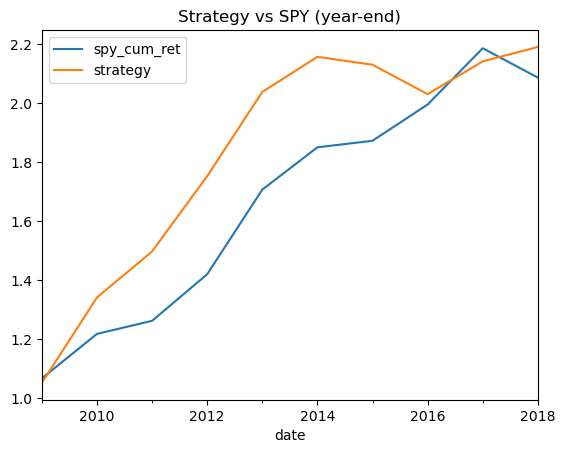

Strategy Sharpe: 0.6956139897451648
SPY Sharpe: 0.4273282941267868
beta: 0.3685887355157008
IR: 0.5529231153599437
alpha: 0.021349918300426058


In [5]:
# Train/Test Splits
df_train = data.loc["2004-01-01":"2009-01-01"]
df_valid = data.loc["2009-04-01":"2009-07-01"]
df_test  = data.loc["2009-10-01":"2010-01-01"]

train_stock_returns = df_train["next_period_return"]
valid_stock_returns = df_valid["next_period_return"]
test_stock_returns  = df_test["next_period_return"]

drop_cols = [
    "ticker", "date",
    "next_period_return", "spy_next_period_return",
    "rel_performance", "pred_rel_return",
    "return", "cum_ret", "spy_cum_ret"
]

train = df_train.reset_index().drop(drop_cols, axis=1, errors="ignore")
valid = df_valid.reset_index().drop(drop_cols, axis=1, errors="ignore")
test  = df_test.reset_index().drop(drop_cols, axis=1, errors="ignore")

# Keep ONLY numeric features
train = train.select_dtypes(include=[np.number]).copy()
valid = valid.select_dtypes(include=[np.number]).copy()
test  = test.select_dtypes(include=[np.number]).copy()

scaler = MinMaxScaler()
float_vars = [c for c in train.columns if np.issubdtype(train[c].dtype, np.number)]

train[float_vars] = scaler.fit_transform(train[float_vars])
valid[float_vars] = scaler.transform(valid[float_vars])
test[float_vars]  = scaler.transform(test[float_vars])

y_train = df_train["rel_performance"].values
y_valid = df_valid["rel_performance"].values
y_test  = df_test["rel_performance"].values

print("Train label counts:", Counter(y_train))
print("Valid label counts:", Counter(y_valid))
print("Test  label counts:", Counter(y_test))

# Base Tree & Feature Importance
t_clf = DecisionTreeClassifier(min_samples_leaf=200, max_depth=15, random_state=123)
t_clf.fit(train, y_train)

print("Train accuracy:", accuracy_score(y_train, t_clf.predict(train)))
print("Valid accuracy:", accuracy_score(y_valid, t_clf.predict(valid)))

fi = pd.DataFrame({"cols": train.columns, "feat_imp": t_clf.feature_importances_}).sort_values("feat_imp", ascending=False)
features = fi[fi["feat_imp"] > 0.0].copy()
cols = features["cols"].values

if len(cols) == 0:
    cols = fi["cols"].head(20).values

print("Num selected features:", len(cols))


# Reduced Feature Set & Rescale
scaler2 = MinMaxScaler()
train_red = pd.DataFrame(scaler2.fit_transform(train[cols].values), columns=cols)
valid_red = pd.DataFrame(scaler2.transform(valid[cols].values), columns=cols)
test_red  = pd.DataFrame(scaler2.transform(test[cols].values), columns=cols)

t_clf.fit(train_red, y_train)

pred_valid = t_clf.predict(valid_red)
pred_test  = t_clf.predict(test_red)

print("Valid pred counts:", Counter(pred_valid))
print("Confusion matrix (valid):\n", confusion_matrix(pred_valid, y_valid))

profit_valid = (pred_valid * df_valid["next_period_return"].values).sum()
profit_test  = (pred_test  * df_test["next_period_return"].values).sum()

print("Valid profit (sum preds*rets):", profit_valid)
print("Test  profit (sum preds*rets):", profit_test)

# Rolling Tree Strategy Backtest
shap_factors = [c for c in cols if c in data.columns]
if len(shap_factors) == 0:
    shap_factors = list(train.columns)

start_dates = [pd.to_datetime("2004-02-01") + pd.DateOffset(months=3*i) for i in range(38)]
end_dates   = [d + pd.DateOffset(months=60) for d in start_dates]

training_frames = [data.loc[d : d + pd.DateOffset(months=60)] for d in start_dates]
test_frames     = [data.loc[d + pd.DateOffset(months=6) : d + pd.DateOffset(months=9)] for d in end_dates]
training_labels = [f["rel_performance"].values for f in training_frames]

scalers = [MinMaxScaler() for _ in range(len(training_frames))]

opt_training_data = []
opt_test_data = []

for i in range(len(training_frames)):
    tr = training_frames[i]
    te = test_frames[i]

    if len(tr) == 0 or len(te) == 0:
        opt_training_data.append(pd.DataFrame(columns=shap_factors))
        opt_test_data.append(pd.DataFrame(columns=shap_factors))
        continue

    X_tr = tr[shap_factors].select_dtypes(include=[np.number]).copy()
    X_te = te[shap_factors].select_dtypes(include=[np.number]).copy()

    # align columns
    common_cols = [c for c in shap_factors if c in X_tr.columns and c in X_te.columns]
    X_tr = X_tr[common_cols]
    X_te = X_te[common_cols]

    if len(common_cols) == 0:
        opt_training_data.append(pd.DataFrame())
        opt_test_data.append(pd.DataFrame())
        continue

    s = scalers[i]
    opt_training_data.append(pd.DataFrame(s.fit_transform(X_tr.values), columns=common_cols))
    opt_test_data.append(pd.DataFrame(s.transform(X_te.values), columns=common_cols))

x = [1.0]
ret = []

n_steps = min(len(start_dates)-1, len(opt_training_data)-1, len(opt_test_data)-1)

for i in range(n_steps):
    if opt_training_data[i].shape[0] == 0 or opt_test_data[i].shape[0] == 0:
        x.append(x[-1])
        ret.append(0.0)
        continue

    y_i = training_labels[i]
    X_i = opt_training_data[i]
    Z_i = opt_test_data[i]

    if len(y_i) != len(X_i):
        m = min(len(y_i), len(X_i))
        y_i = y_i[:m]
        X_i = X_i.iloc[:m].copy()

    t_clf.fit(X_i, y_i)

    preds = t_clf.predict(Z_i)
    profit_i = (preds * test_frames[i]["next_period_return"].values[:len(preds)]).sum()

    ret.append(profit_i)
    num_names = len(Z_i)
    x.append(x[i] + (x[i] / num_names) * profit_i)

plt.plot(x)
plt.title("Tree strategy cumulative value")
plt.show()


# SPY Buy-And-Hold Comparison
if "spy_cum_ret" not in data.columns:
    raise ValueError("Need 'spy_cum_ret' in data to compare with SPY buy-and-hold.")

SPY = (
    data.reset_index()[["date", "spy_cum_ret"]]
    .drop_duplicates("date")
    .set_index("date")
    .sort_index()
)

SPY = SPY.loc["2009-08-03":"2024-08-01"].resample("QE").ffill()
SPY["spy_cum_ret"] = SPY["spy_cum_ret"] - SPY["spy_cum_ret"].iloc[0] + 1.0

m = min(len(SPY), len(x))
SPY = SPY.iloc[:m].copy()
SPY["strategy"] = x[:m]

SPY.plot()
plt.title("Strategy vs SPY (quarterly)")
plt.show()

SPY_y = SPY.resample("YE").ffill()
SPY_y.plot()
plt.title("Strategy vs SPY (year-end)")
plt.show()

strategy_ret = (SPY["strategy"] - 1.0).diff()
spy_ret = (SPY["spy_cum_ret"] - 1.0).diff()

strategy_mean = strategy_ret.mean()
strategy_std  = strategy_ret.std()
spy_mean      = spy_ret.mean()
spy_std       = spy_ret.std()

print("Strategy Sharpe:", strategy_mean / strategy_std)
print("SPY Sharpe:", spy_mean / spy_std)

sr = strategy_ret.values[1:]
mr = spy_ret.values[1:]

beta = (np.cov(mr, sr) / np.var(mr))[1, 0]
resid = sr - beta * mr
IR = np.mean(resid) / np.std(resid)
alpha = np.mean(resid)

print("beta:", beta)
print("IR:", IR)
print("alpha:", alpha)

### Q3

#### Prepare Data

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from matplotlib.patches import Rectangle
from matplotlib.collections import PatchCollection
from matplotlib import cm

n = 1000
x = np.random.uniform(0, 1, n)
y = np.random.uniform(0, 1, n)
target = np.random.uniform(x + y, 6)

data1 = pd.DataFrame({"x": x, "y": y})

#### Regression Tree

In [7]:
tree_1 = DecisionTreeRegressor(max_depth=5, min_samples_leaf=50, random_state=0)
tree_1.fit(data1, target)

,criterion,'squared_error'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,50
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


#### Leaf Rectangles & Average Target Coloring (Copied from "Visualizing Trees")

In [8]:
def reg_boxes(tree, data, y, cmap=cm.viridis):
    n_nodes = tree.tree_.node_count
    children_left = tree.tree_.children_left
    children_right = tree.tree_.children_right
    feature = tree.tree_.feature
    threshold = tree.tree_.threshold

    def split(i):
        return children_left[i], children_right[i]

    def parent(i):
        for j in range(n_nodes):
            l, r = split(j)
            if l == i or r == i:
                return j
        return None

    def box(i):
        if i == 0:
            return (0.0, 0.0), (1.0, 1.0)

        j = parent(i)
        (a, b), (c, d) = box(j)
        t = threshold[j]

        if feature[j] == 0:  # split on x
            if i == split(j)[0]:
                return (a, b), (t, d)
            else:
                return (t, b), (c, d)

        if feature[j] == 1:  # split on y
            if i == split(j)[0]:
                return (a, b), (c, t)
            else:
                return (a, t), (c, d)

        return (a, b), (c, d)

    boxes = [box(i) for i in range(n_nodes)]
    leaves = [i for i in range(n_nodes) if split(i) == (-1, -1)]

    norm = plt.Normalize(vmin=np.min(y), vmax=np.max(y))

    rects = []
    colors = []

    for leaf in leaves:
        (a, b), (c, d) = boxes[leaf]
        rects.append(Rectangle((a, b), c - a, d - b))

        idx = (
            (data["x"].values > a) & (data["x"].values <= c) &
            (data["y"].values > b) & (data["y"].values <= d)
        )

        v = np.mean(y[idx]) if np.any(idx) else np.min(y)
        colors.append(cmap(norm(v)))

    pc = PatchCollection(rects, facecolor=colors, edgecolor="k", linewidths=2, alpha=0.9)

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.scatter(data["x"], data["y"], c=y, s=10, alpha=0.35)
    ax.add_collection(pc)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    plt.show()

#### Experiment with Different Color Schemes

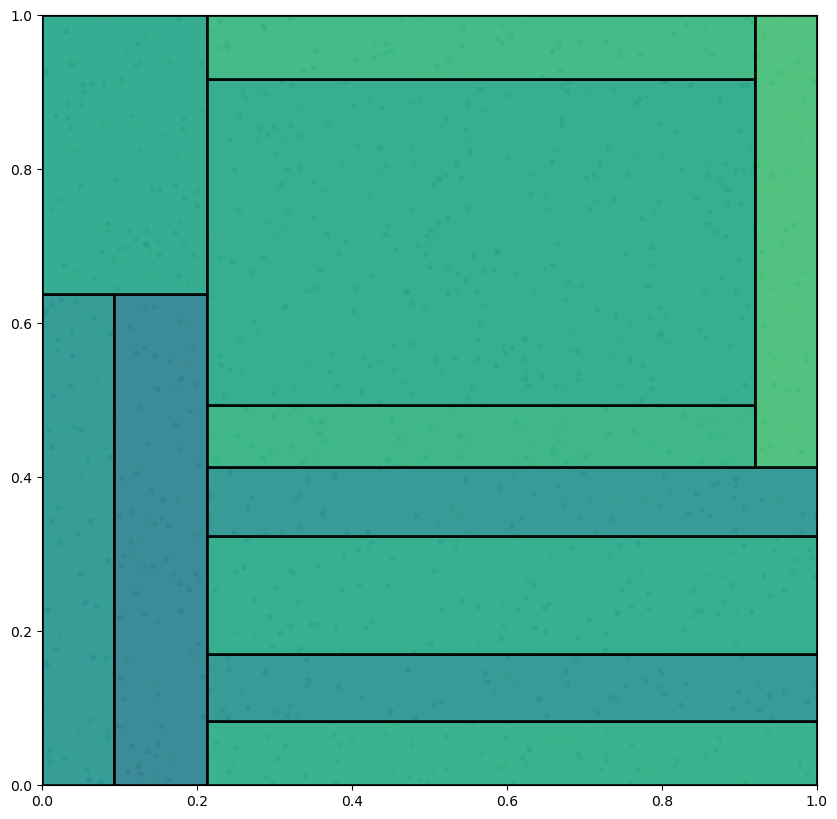

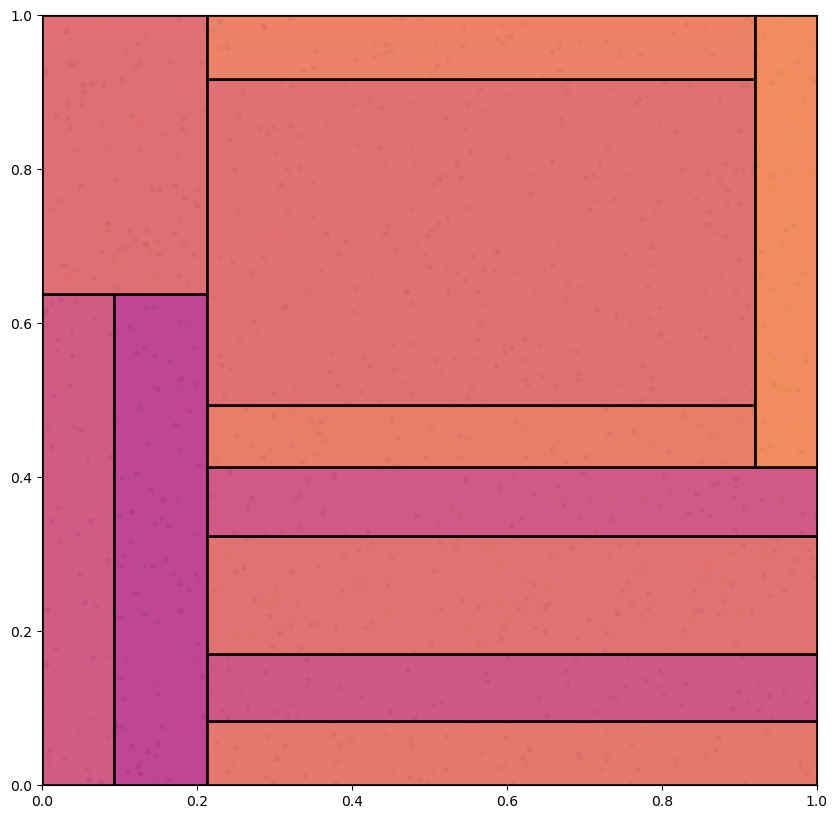

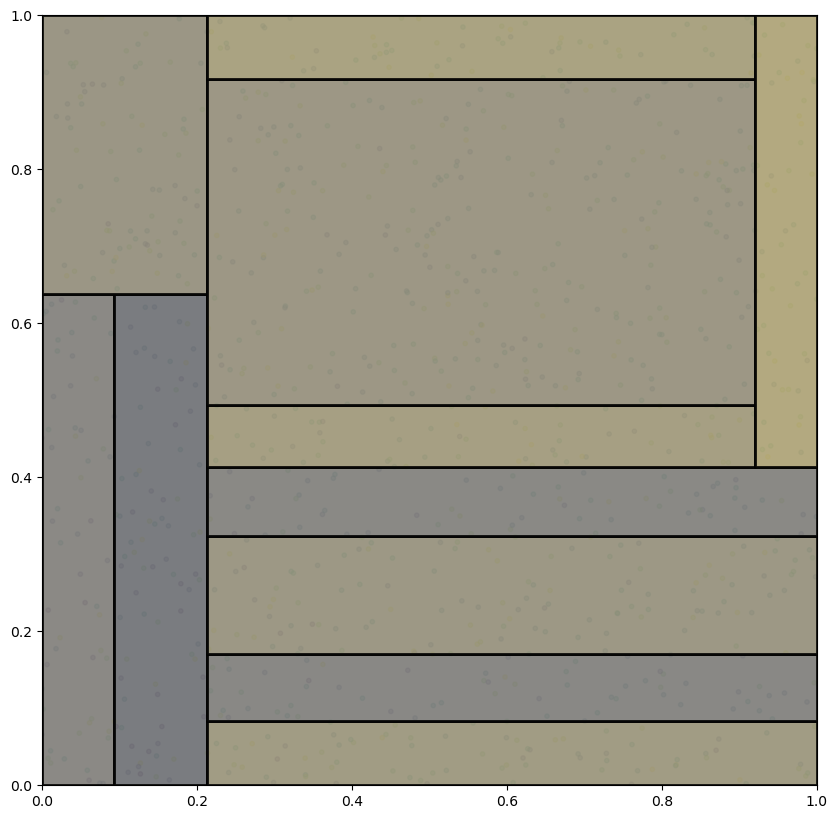

In [9]:
for cmap in [cm.viridis, cm.plasma, cm.cividis]:
    reg_boxes(tree_1, data1, target, cmap=cmap)